### ДЗ 3: семантическая сегментация

In [140]:
# импорты необходимых библиотек

import importlib.util
import subprocess
import sys
packages = {"torch": "torch>=2.5", "numpy": "numpy", "matplotlib": "matplotlib",
            "PIL": "Pillow>=10", "scipy": "scipy"}
missing = [package for module, package in packages.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", *missing])

import csv
import random
import time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from PIL import Image
from scipy import ndimage
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import Dataset, DataLoader, ConcatDataset

SEED = 42
SIZE = 96             # уменьшенное исходное изображение
# ищем крупные фрагменты микропластика, поэтому для обучения используем целое изображение, а не фрагмент

BATCH_SIZE = 8
EPOCHS = 50
LEARNING_RATE = 0.001

WORK = Path(".")
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.set_num_threads(4)

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

set_seed(SEED)
print("PyTorch:", torch.__version__, "| устройство:", DEVICE)


PyTorch: 2.15.0+cu132 | устройство: cuda


In [141]:
# загрузка данных из папки microplastic (она должна лежать рядом с ноутбуком)

DATA = Path('microplastic')

def split_names(split):
    return sorted(path.stem for path in (DATA / split / 'images').glob('*.jpg'))

train_names = split_names("train")
val_names = split_names("val")
test_names = split_names("test")
assert len(train_names) == 1391 and len(val_names) == 351 and len(test_names) == 755

print(f"train: {len(train_names)}, validation: {len(val_names)}, test: {len(test_names)}")

train: 1391, validation: 351, test: 755


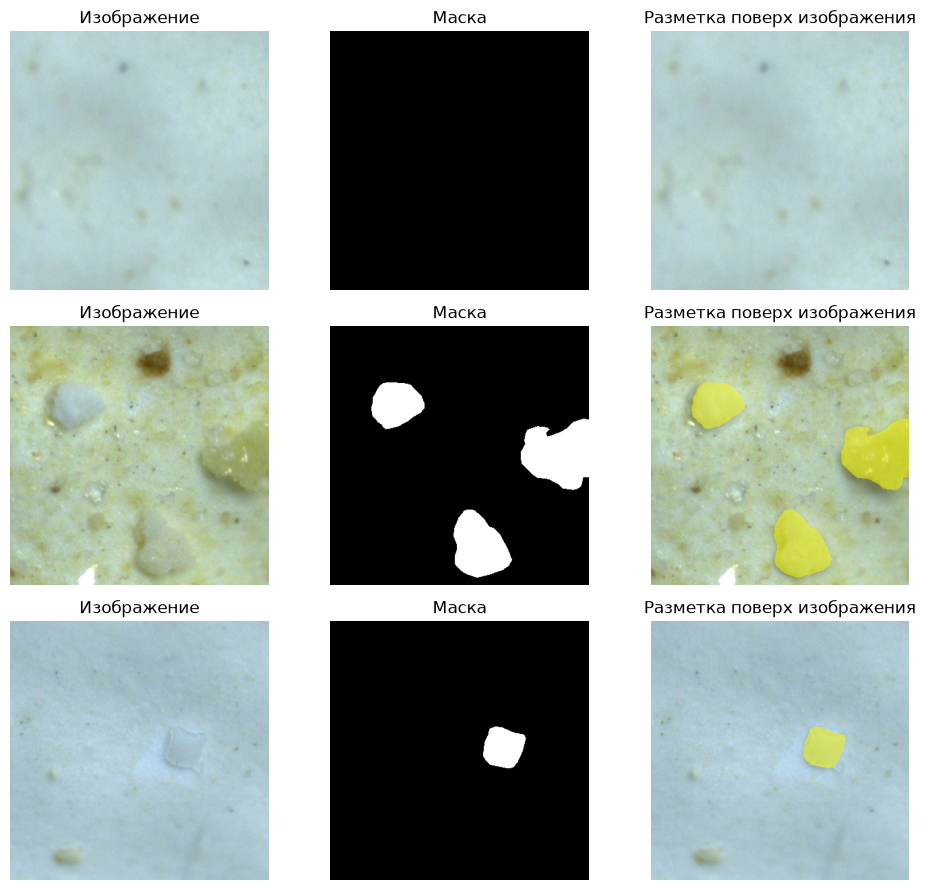

Изображение: (384, 384, 3)
Маска: (384, 384)


In [142]:
def load_image(path):
    with Image.open(path) as source:
        image = np.asarray(source.convert("RGB"), dtype=np.float32)
    return image / 255.0

def read_pair(name, split="train"):
    image = load_image(DATA / split / "images" / f"{name}.jpg")
    with Image.open(DATA / split / "masks" / f"{name}.png") as source:
        mask = np.asarray(source, dtype=np.uint8)
    return image, mask

def show_examples(names):
    fig, axes = plt.subplots(len(names), 3, figsize=(10, 3 * len(names)), squeeze=False)
    for row, name in zip(axes, names):
        image, mask = read_pair(name)
        row[0].imshow(image)
        row[1].imshow(mask, cmap="gray", vmin=0, vmax=1)
        row[2].imshow(image)
        row[2].imshow(np.ma.masked_where(mask != 1, mask), cmap="autumn", alpha=.5, vmin=0, vmax=1)
        for ax, title in zip(row, ["Изображение", "Маска", "Разметка поверх изображения"]):
            ax.set_title(title); ax.axis("off")
    plt.tight_layout(); plt.show()

show_examples([train_names[i] for i in [0, 20, 40]])
image, mask = read_pair(train_names[0])
print("Изображение:", image.shape)
print("Маска:", mask.shape)

In [143]:
def image_tensor(image):
    # трехканальное изображение, поэтому только преобразование размерностей
    return torch.from_numpy(np.ascontiguousarray(image)).float().permute(2, 0, 1)

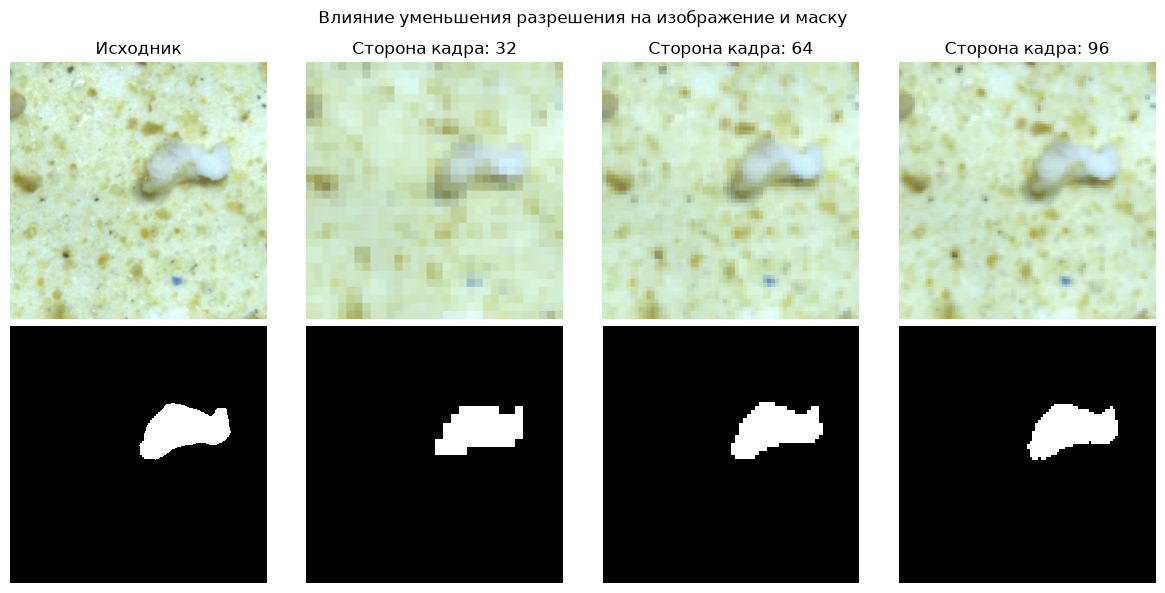

In [144]:
# как изменение разрешения влияет на изображение и маску

def show_resize_detail(name):
    image, mask = read_pair(name)
    height, width = image.shape[:2]
    fig, axes = plt.subplots(2, 4, figsize=(12, 6))
    for column, size in enumerate([None, 32, 64, 96]):
        photo = Image.fromarray(np.rint(image * 255).astype(np.uint8))
        target = Image.fromarray(mask)
        if size is not None:
            small = (round(width * size / height), size)
            photo = photo.resize(small, Image.Resampling.BILINEAR).resize((width, height), Image.Resampling.NEAREST)
            target = target.resize(small, Image.Resampling.NEAREST).resize((width, height), Image.Resampling.NEAREST)
        axes[0, column].imshow(np.array(photo))
        axes[1, column].imshow(np.array(target), cmap="gray", vmin=0, vmax=1, interpolation="nearest")
        axes[0, column].set_title("Исходник" if size is None else f"Сторона кадра: {size}")
        for ax in axes[:, column]: ax.axis("off")
    fig.suptitle("Влияние уменьшения разрешения на изображение и маску")
    plt.tight_layout(); plt.show()

show_resize_detail(train_names[2])

По визуализации видно, что при уменьшении изображений до 96*96 они в целом сохраняются, хотя некоторые мелкие детали теряются. Поскольку для сегментации необходимо выделять достаточно крупные фрагменты, такое разрешение допустимо. 

Более того, уменьшение разрешения сокращает время обучения.

In [145]:
# получение обучающих примеров

class MicroplasticDataset(Dataset):
    def __init__(self, names, split="train", augment=False, full_mask=False):
        self.names = list(names)
        self.split = split
        self.augment = augment
        self.pairs = []
        self.full_mask = full_mask

        for name in self.names:
            image, mask = read_pair(name, split)
            # уменьшение изображения
            photo = Image.fromarray(np.rint(image * 255).astype(np.uint8))
            image = np.asarray(photo.resize((SIZE, SIZE), Image.Resampling.BILINEAR), dtype=np.float32) / 255.0
            # уменьшение маски
            small_mask = np.asarray(Image.fromarray(mask).resize((SIZE, SIZE), Image.Resampling.NEAREST), dtype=np.uint8)
            # на валидации сохраняем исходную маску 384x384
            self.pairs.append((image, small_mask, mask if split == "val" else None))

        self.rng = np.random.default_rng(SEED)

    def __len__(self):
        return len(self.names)

    def __getitem__(self, index):
        image, mask, original_mask = self.pairs[index]
        if self.augment:
            for axis in [0, 1]:
                if self.rng.random() < .5:
                    image, mask = np.flip(image, axis), np.flip(mask, axis)
            k = int(self.rng.integers(4))
            image, mask = np.rot90(image, k), np.rot90(mask, k)
        if self.full_mask:
            mask = original_mask
        
        return (image_tensor(image), torch.from_numpy(np.array(mask, copy=True)).long())

train_data = MicroplasticDataset(train_names, "train", augment=True)
val_data = MicroplasticDataset(val_names, "val", full_mask=True)
val_loader = DataLoader(val_data, batch_size=1, shuffle=False, num_workers=0)
images, masks = next(iter(DataLoader(train_data, batch_size=BATCH_SIZE)))
print("Train:", images.shape, masks.shape)
print("Validation:", val_data[0][0].shape, val_data[0][1].shape)

Train: torch.Size([8, 3, 96, 96]) torch.Size([8, 96, 96])
Validation: torch.Size([3, 96, 96]) torch.Size([384, 384])


In [146]:
# выбор модели

def conv_block(in_channels, out_channels):
    return nn.Sequential(
        nn.Conv2d(in_channels, out_channels, 3, padding=1, bias=False),
        nn.BatchNorm2d(out_channels), nn.ReLU(),
        nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False),
        nn.BatchNorm2d(out_channels), nn.ReLU(),
    )

def up_to(x, reference):
    return F.interpolate(x, size=reference.shape[-2:], mode="bilinear", align_corners=False)

class MiniUNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.enc1 = conv_block(3, 12)
        self.enc2 = conv_block(12, 24)
        self.enc3 = conv_block(24, 48)
        self.center = conv_block(48, 96)
        self.dec3 = conv_block(96 + 48, 48)
        self.dec2 = conv_block(48 + 24, 24)
        self.dec1 = conv_block(24 + 12, 12)
        self.head = nn.Conv2d(12, 2, 1)

    def forward(self, x):
        first = self.enc1(x)
        second = self.enc2(F.max_pool2d(first, 2))
        third = self.enc3(F.max_pool2d(second, 2))
        x = self.center(F.max_pool2d(third, 2))
        x = self.dec3(torch.cat([up_to(x, third), third], dim=1))
        x = self.dec2(torch.cat([up_to(x, second), second], dim=1))
        x = self.dec1(torch.cat([up_to(x, first), first], dim=1))
        return self.head(x)

shape_model = MiniUNet().eval()
with torch.inference_mode():
    print("Вход:", images[:2].shape, "-> logits:", shape_model(images[:2]).shape)
del shape_model

Вход: torch.Size([2, 3, 96, 96]) -> logits: torch.Size([2, 2, 96, 96])


In [147]:
# вычисление качества сегментации

def confusion_matrix(target, prediction):
    valid = target != 255
    codes = 2 * target[valid].astype(np.int64) + prediction[valid].astype(np.int64)
    return np.bincount(codes, minlength=4).reshape(2, 2)

def class_iou(matrix):
    intersection = np.diag(matrix).astype(float)
    union = matrix.sum(0) + matrix.sum(1) - intersection
    return np.divide(intersection, union, out=np.full(2, np.nan), where=union > 0)

def mean_iou(matrix):
    if matrix.sum() == 0:
        raise ValueError("Нет пикселей для оценки")
    return float(np.nanmean(class_iou(matrix)))

In [148]:
# выбор функции потерь
# поскольку фон занимает большую часть пикселей, обычная CrossEntropy может приводить к тому, 
# что модель предсказывает класс 0, попробуем взвешенную CrossEntropy 

criterion = nn.CrossEntropyLoss(weight=torch.tensor([1., 3.], device=DEVICE))

def train_epoch(model, loader, optimizer):
    model.train()
    total_loss, total_pixels = 0., 0
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        count = int((y != 255).sum())
        if count == 0:
            continue
        optimizer.zero_grad(set_to_none=True)
        loss = criterion(model(x), y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * count
        total_pixels += count
    return total_loss / total_pixels

def boundary_counts(target, prediction):
    # Контур = маска минус эрозия. Две dilation дают допуск 2.
    foreground, predicted = target == 1, prediction == 1
    true_edge = foreground ^ ndimage.binary_erosion(foreground)
    pred_edge = predicted ^ ndimage.binary_erosion(predicted)
    matched_pred = (pred_edge & ndimage.binary_dilation(true_edge, iterations=2)).sum()
    matched_true = (true_edge & ndimage.binary_dilation(pred_edge, iterations=2)).sum()
    return np.array([matched_pred, pred_edge.sum(), matched_true, true_edge.sum()], dtype=np.int64)

@torch.inference_mode()
def evaluate(model, loader):
    model.eval()
    matrix = np.zeros((2, 2), dtype=np.int64)
    edges = np.zeros(4, dtype=np.int64)
    scores, offset = [], 0
    for x, targets in loader:
        logits = model(x.to(DEVICE))
        logits = F.interpolate(logits, size=targets.shape[-2:], mode="bilinear", align_corners=False)
        predictions = logits.argmax(1).cpu().numpy()
        for prediction, target in zip(predictions, targets.numpy()):
            counts = confusion_matrix(target, prediction)
            matrix += counts
            edges += boundary_counts(target, prediction)
            scores.append((float(class_iou(counts)[1]), loader.dataset.names[offset]))
            offset += 1
    precision = edges[0] / max(edges[1], 1)
    recall = edges[2] / max(edges[3], 1)
    boundary_f1 = 2 * precision * recall / max(precision + recall, 1e-12)
    return mean_iou(matrix), class_iou(matrix), scores, float(boundary_f1)

# предсказание с подобранным порогом
@torch.inference_mode()
def predict(model, image, threshold=0.5):
    model.eval()
    # уменьшаем изображение так же, как при обучении
    if image.shape[:2] != (SIZE, SIZE):
        photo = Image.fromarray(np.rint(image * 255).astype(np.uint8))
        image = np.asarray(photo.resize((SIZE, SIZE), Image.Resampling.BILINEAR), dtype=np.float32) / 255.0
    logits = model(image_tensor(image)[None].to(DEVICE))
    logits = F.interpolate(logits, size=(384, 384), mode="bilinear", align_corners=False)
    return (logits.softmax(1)[0, 1] > threshold).cpu().numpy().astype(np.uint8)

def fit(model_class, tag):
    set_seed(SEED)
    train_data.rng = np.random.default_rng(SEED)
    loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True, num_workers=0,
                        generator=torch.Generator().manual_seed(SEED))
    model = model_class().to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    # качество продолжало расти, даже при увеличении числа эпох
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=0.0001)
    path = WORK / f"{tag}.pt"
    best, history, snapshots = -1., [], {}
    started = time.perf_counter()
    for epoch in range(1, EPOCHS + 1):
        loss = train_epoch(model, loader, optimizer)
        scheduler.step()
        score, _, _, _ = evaluate(model, val_loader)
        history.append({"epoch": epoch, "train_loss": loss, "val_miou": score})
        if epoch in {1, max(1, EPOCHS // 2), EPOCHS}:
            snapshots[epoch] = predict(model, val_data.pairs[0][0])
        if score > best:
            best = score
            torch.save({"model": model.state_dict(), "architecture": model_class.__name__,
                        "input_channels": 3, "image_size": SIZE,
                        "class_names": ["background", "microplastic"],
                        "preprocessing": f"RGB / 255, resize to {SIZE}x{SIZE}",
                        "inference": "resize logits to 384x384, argmax",
                        "seed": SEED, "epoch": epoch, "val_miou": score,
                        "batch_size": BATCH_SIZE, "epochs": EPOCHS, "learning_rate": LEARNING_RATE,
                        "augmentation": "paired flips on both axes, rot90",
                        "splits": {"train": train_names, "val": val_names, "test": test_names}}, path)
        print(f"{tag} {epoch:02d}/{EPOCHS}: loss {loss:.3f} | val mIoU {score:.4f}", flush=True)
    elapsed = time.perf_counter() - started
    checkpoint = torch.load(path, map_location=DEVICE, weights_only=True)
    model.load_state_dict(checkpoint["model"])
    score, ious, _, boundary_f1 = evaluate(model, val_loader)
    print(f"Лучший val mIoU: {score:.4f}, эпоха {checkpoint['epoch']}; {elapsed / 60:.1f} мин.")
    return model, {"name": tag, "path": path, "miou": score, "foreground_iou": float(ious[1]),
                   "boundary_f1": boundary_f1, "epoch": checkpoint["epoch"], "seconds": elapsed,
                   "parameters": sum(p.numel() for p in model.parameters()),
                   "history": history, "snapshots": snapshots}

model, result = fit(MiniUNet, "unet")

unet 01/50: loss 0.403 | val mIoU 0.4010
unet 02/50: loss 0.311 | val mIoU 0.5359
unet 03/50: loss 0.283 | val mIoU 0.5963
unet 04/50: loss 0.261 | val mIoU 0.6177
unet 05/50: loss 0.247 | val mIoU 0.6083
unet 06/50: loss 0.236 | val mIoU 0.5789
unet 07/50: loss 0.233 | val mIoU 0.6545
unet 08/50: loss 0.213 | val mIoU 0.6199
unet 09/50: loss 0.209 | val mIoU 0.6369
unet 10/50: loss 0.201 | val mIoU 0.6652
unet 11/50: loss 0.196 | val mIoU 0.6850
unet 12/50: loss 0.189 | val mIoU 0.6947
unet 13/50: loss 0.176 | val mIoU 0.7058
unet 14/50: loss 0.166 | val mIoU 0.6883
unet 15/50: loss 0.169 | val mIoU 0.7489
unet 16/50: loss 0.163 | val mIoU 0.6958
unet 17/50: loss 0.152 | val mIoU 0.7352
unet 18/50: loss 0.151 | val mIoU 0.6808
unet 19/50: loss 0.148 | val mIoU 0.7243
unet 20/50: loss 0.143 | val mIoU 0.7614
unet 21/50: loss 0.133 | val mIoU 0.7527
unet 22/50: loss 0.135 | val mIoU 0.7386
unet 23/50: loss 0.135 | val mIoU 0.7600
unet 24/50: loss 0.128 | val mIoU 0.7534
unet 25/50: loss

In [149]:
# подбор порога на validation

@torch.inference_mode()
def check_thresholds(model):
    model.eval()
    thresholds = [0.4, 0.45, 0.5, 0.55, 0.6, 0.65, 0.7]
    matrices = [np.zeros((2, 2), dtype=np.int64) for _ in thresholds]
    for x, targets in val_loader:
        logits = model(x.to(DEVICE))
        logits = F.interpolate(logits, size=targets.shape[-2:], mode="bilinear", align_corners=False)
        probabilities = logits.softmax(1)[:, 1].cpu().numpy()
        for i, threshold in enumerate(thresholds):
            predictions = (probabilities > threshold).astype(np.uint8)
            for prediction, target in zip(predictions, targets.numpy()):
                matrices[i] += confusion_matrix(target, prediction)
    scores = [mean_iou(matrix) for matrix in matrices]
    for threshold, score in zip(thresholds, scores):
        print(f"Порог {threshold:.2f}: mIoU = {score:.4f}")
    return thresholds[np.argmax(scores)]

THRESHOLD = check_thresholds(model)
print("Выбранный порог:", THRESHOLD)

Порог 0.40: mIoU = 0.8296
Порог 0.45: mIoU = 0.8346
Порог 0.50: mIoU = 0.8383
Порог 0.55: mIoU = 0.8406
Порог 0.60: mIoU = 0.8415
Порог 0.65: mIoU = 0.8391
Порог 0.70: mIoU = 0.8337
Выбранный порог: 0.6


In [150]:
# итоговое обучение модели на train + val

final_train_data = MicroplasticDataset(train_names, "train", augment=True)
final_val_data = MicroplasticDataset(val_names, "val", augment=True)
final_data = ConcatDataset([final_train_data, final_val_data])

def fit_final(model_class, tag):
    set_seed(SEED)
    final_train_data.rng = np.random.default_rng(SEED)
    final_val_data.rng = np.random.default_rng(SEED + 1)
    loader = DataLoader(final_data, batch_size=BATCH_SIZE, shuffle=True, num_workers=0, 
                        generator=torch.Generator().manual_seed(SEED))
    model = model_class().to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=0.0001)
    path = WORK / f"{tag}.pt"
    final_epochs = int(result["epoch"])
    for epoch in range(1, final_epochs + 1):
        loss = train_epoch(model, loader, optimizer)
        scheduler.step()
        print(f"{tag} {epoch:02d}/{final_epochs}: loss {loss:.3f}", flush=True)

    torch.save({"model": model.state_dict(), "architecture": model_class.__name__,
                            "input_channels": 3, "image_size": SIZE,
                            "class_names": ["background", "microplastic"],
                            "preprocessing": f"RGB / 255; resize to {SIZE}х{SIZE}",
                            "inference": "resize logits to 384x384, argmax", 
                            "seed": SEED, "epoch": final_epochs, "threshold": float(THRESHOLD),
                            "batch_size": BATCH_SIZE, "epochs": final_epochs, 
                            "scheduler_T_max": EPOCHS, "learning_rate": LEARNING_RATE, 
                            "augmentation": "paired flips on both axes, rot90",
                            "splits": {"train": train_names, "val": val_names, "test": test_names}}, path)

    print(f"Модель train+val сохранена: {path}")
    return model, path


final_model, final_checkpoint_path = fit_final(MiniUNet, "unet_res")

unet_res 01/47: loss 0.382
unet_res 02/47: loss 0.283
unet_res 03/47: loss 0.270
unet_res 04/47: loss 0.246
unet_res 05/47: loss 0.241
unet_res 06/47: loss 0.224
unet_res 07/47: loss 0.208
unet_res 08/47: loss 0.196
unet_res 09/47: loss 0.188
unet_res 10/47: loss 0.182
unet_res 11/47: loss 0.179
unet_res 12/47: loss 0.165
unet_res 13/47: loss 0.159
unet_res 14/47: loss 0.158
unet_res 15/47: loss 0.153
unet_res 16/47: loss 0.135
unet_res 17/47: loss 0.133
unet_res 18/47: loss 0.134
unet_res 19/47: loss 0.124
unet_res 20/47: loss 0.125
unet_res 21/47: loss 0.114
unet_res 22/47: loss 0.120
unet_res 23/47: loss 0.112
unet_res 24/47: loss 0.106
unet_res 25/47: loss 0.104
unet_res 26/47: loss 0.099
unet_res 27/47: loss 0.092
unet_res 28/47: loss 0.093
unet_res 29/47: loss 0.094
unet_res 30/47: loss 0.092
unet_res 31/47: loss 0.084
unet_res 32/47: loss 0.080
unet_res 33/47: loss 0.078
unet_res 34/47: loss 0.080
unet_res 35/47: loss 0.072
unet_res 36/47: loss 0.072
unet_res 37/47: loss 0.071
u

In [151]:
# формирование итогового CSV 

sys.path.insert(0, str(DATA.resolve()))
from submission import encode_rle

final_model.eval()

with (WORK / "sample_submission.csv").open(newline="", encoding="utf-8") as file:
    rows = list(csv.DictReader(file))

assert len(rows) == len(test_names) == 755
assert {row["id"] for row in rows} == set(test_names)

# получаем предсказания на test
for row in rows:
    name = row["id"]
    image = load_image(DATA / "test" / "images" / f"{name}.jpg")
    prediction = predict(final_model, image, threshold=THRESHOLD)
    row["rle"] = encode_rle(prediction)

submission_path = WORK / "submission.csv"

with submission_path.open("w", newline="", encoding="utf-8") as file:
    writer = csv.DictWriter(file, fieldnames=["id", "rle"])
    writer.writeheader()
    writer.writerows(rows)

print("CSV:", submission_path, "| изображений:", len(rows))

CSV: submission.csv | изображений: 755
